In [11]:
from rtlsdr import RtlSdr
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
%matplotlib inline

In [12]:
len_in = 1024 * 1500
len_out = int(len_in / 40)

resize = 1 / 40

In [13]:
# increase usb memory buffer
!echo 0 > /sys/module/usbcore/parameters/usbfs_memory_mb

In [14]:
sdr = RtlSdr()

fc = 99750000
fs = 1920000
ppm = 60

sdr.sample_rate = fs
sdr.center_freq = fc
sdr.freq_correction = ppm
sdr.gain = "auto"

In [15]:
num_bytes_to_read = len_in * 2

# raw_data = sdr.read_bytes(num_bytes_to_read)
# print(len(raw_data))
# print(raw_data[0:20])

# raw_uint8 = np.array(raw_data, dtype=np.uint8)
# print(len(raw_uint8))
# print(raw_uint8[0:20])

# raw_int8 = (raw_uint8.astype(np.int16) - 128).astype(np.int8)
# print(len(raw_int8))
# print(raw_int8[0:20])

# packed_samples = raw_int8.view(np.uint16)
# print(len(packed_samples))
# print(packed_samples[0:10])

###########################

complex_samples = sdr.read_samples(len_in)
print(len(complex_samples))
print(complex_samples[0:10])
print(type(complex_samples[0]))

scaled_real = (complex_samples.real * 127).astype(np.int8)
scaled_imag = (complex_samples.imag * 127).astype(np.int8)

interleaved_int8 = np.empty(len(complex_samples) * 2, dtype=np.int8)

interleaved_int8[0::2] = scaled_real
interleaved_int8[1::2] = scaled_imag
print(len(interleaved_int8))
print(interleaved_int8[0:20])

packed_samples = interleaved_int8.view(np.uint16)
print(len(packed_samples))
print(packed_samples[0:10])

#################################

# raw_data = sdr.read_bytes(num_bytes_to_read)
# print(len(raw_data))
# print(raw_data[0:20])

# arr = np.ctypeslib.as_array(raw_data)

# samples = arr.astype(np.float64).view(np.complex128)
# print(len(samples))
# print(samples[0:10])

sdr.close()

1536000
[ 0.70980392-1.j         -0.62352941+0.01176471j -0.30980392-0.91372549j
  0.14509804+0.00392157j -0.05882353+0.80392157j  0.31764706+0.88235294j
 -0.83529412-0.16078431j -0.43529412-0.80392157j  0.54509804+0.75686275j
  0.39607843-0.22352941j]
<class 'numpy.complex128'>
3072000
[  90 -127  -79    1  -39 -116   18    0   -7  102   40  112 -106  -20
  -55 -102   69   96   50  -28]
1536000
[33114   433 36057    18 26361 28712 60566 39625 24645 58418]


In [16]:
from pynq import Overlay, allocate

ol = Overlay("./base.bit")

/usr/local/share/pynq-venv/lib/python3.8/site-packages/pynq/bitstream.py:151: UserWarning: The provided name './base.bit' resulted in multiple possible matches:
 - /home/xilinx/jupyter_notebooks/audio/base.bit
 - /usr/local/share/pynq-venv/lib/python3.8/site-packages/pynq/overlays/./base/./base.bit
The first entry of this list, '/home/xilinx/jupyter_notebooks/audio/base.bit', will be used, please provide the full path in case your target file was a different one in this list.
  warnings.warn(msg, UserWarning)


In [17]:
print(ol.ip_dict.keys())

dict_keys(['rtl_sdr/axi_dma_0', 'switches_gpio', 'btns_gpio', 'rgbleds_gpio', 'leds_gpio', 'video/axi_vdma_0', 'video/axi_dynclk_0', 'video/v_tc_0', 'simple_io_0', 'axi_quad_spi_0', 'lcd_gpio', 'ps7_0'])


In [18]:
# dma = ol.axi_dma_0
dma = ol.rtl_sdr.axi_dma_0

/usr/local/share/pynq-venv/lib/python3.8/site-packages/pynq/overlay.py:681: UserWarning: Interrupt mm2s_introut not created: Could not find UIO device for interrupt pin for IRQ number 64
  warnings.warn('Interrupt {} not created: {}'.format(
/usr/local/share/pynq-venv/lib/python3.8/site-packages/pynq/overlay.py:681: UserWarning: Interrupt s2mm_introut not created: Could not find UIO device for interrupt pin for IRQ number 65
  warnings.warn('Interrupt {} not created: {}'.format(


In [19]:
input_buffer = allocate(shape=(len_in,), dtype=np.uint16)
output_buffer = allocate(shape=(len_out,), dtype=np.int16)

In [20]:
print(f"Input Buffer Address: {hex(input_buffer.device_address)}")
print(f"Output Buffer Address: {hex(output_buffer.device_address)}")

Input Buffer Address: 0x16900000
Output Buffer Address: 0x16860000


In [21]:
np.copyto(input_buffer, packed_samples)
print(input_buffer[0:10])
print(output_buffer[0:10])

[33114   433 36057    18 26361 28712 60566 39625 24645 58418]
[0 0 0 0 0 0 0 0 0 0]


In [22]:
dma.sendchannel.transfer(input_buffer)
dma.recvchannel.transfer(output_buffer)

In [23]:
dma.register_map

RegisterMap {
  MM2S_DMACR = Register(RS=1, Reset=0, Keyhole=0, Cyclic_BD_Enable=0, IOC_IrqEn=0, Dly_IrqEn=0, Err_IrqEn=0, IRQThreshold=1, IRQDelay=0),
  MM2S_DMASR = Register(Halted=0, Idle=1, SGIncld=0, DMAIntErr=0, DMASlvErr=0, DMADecErr=0, SGIntErr=0, SGSlvErr=0, SGDecErr=0, IOC_Irq=1, Dly_Irq=0, Err_Irq=0, IRQThresholdSts=0, IRQDelaySts=0),
  MM2S_CURDESC = Register(Current_Descriptor_Pointer=0),
  MM2S_CURDESC_MSB = Register(Current_Descriptor_Pointer=0),
  MM2S_TAILDESC = Register(Tail_Descriptor_Pointer=0),
  MM2S_TAILDESC_MSB = Register(Tail_Descriptor_Pointer=0),
  MM2S_SA = Register(Source_Address=378535936),
  MM2S_SA_MSB = Register(Source_Address=0),
  MM2S_LENGTH = Register(Length=3072000),
  SG_CTL = Register(SG_CACHE=0, SG_USER=0),
  S2MM_DMACR = Register(RS=1, Reset=0, Keyhole=0, Cyclic_BD_Enable=0, IOC_IrqEn=0, Dly_IrqEn=0, Err_IrqEn=0, IRQThreshold=1, IRQDelay=0),
  S2MM_DMASR = Register(Halted=0, Idle=1, SGIncld=0, DMAIntErr=0, DMASlvErr=0, DMADecErr=0, SGIntErr=0, 

In [24]:
audio_data = output_buffer.astype(np.float32) / 32768.0
print(len(audio_data))
print(audio_data[0:20])
print(output_buffer[0:20])

38400
[ 0.0000000e+00  3.0517578e-05 -9.1552734e-04  1.6784668e-03
 -3.1433105e-03 -1.1260986e-02  1.0375977e-03 -7.2021484e-03
  5.3405762e-03 -7.0495605e-03 -5.8288574e-03  5.1269531e-03
 -1.9012451e-02  3.1982422e-02  5.0720215e-02 -1.1730957e-01
 -1.6339111e-01 -3.9520264e-02 -6.2438965e-02 -7.2998047e-02]
[    0     1   -30    55  -103  -369    34  -236   175  -231  -191   168
  -623  1048  1662 -3844 -5354 -1295 -2046 -2392]


In [25]:
from IPython.display import Audio

Audio(audio_data, autoplay=True, rate=48000, normalize=False)

In [26]:
del input_buffer, output_buffer

In [27]:
np.save("samples_received", complex_samples)

In [28]:
def downsample(x, M, p=0):  
    if not isinstance(M, int):
        raise TypeError("M must be an int")
    x = x[0:int(np.floor(len(x) / M)) * M]
    x = x.reshape((int(np.floor(len(x) / M)), M))
    y = x[:,p]
    return y

def fm_discrim(x):
    X = np.real(x)
    Y = np.imag(x)
    b = np.array([1, -1])
    dY = signal.lfilter(b, 1, Y)
    dX = signal.lfilter(b, 1, X)
    discriminated = (X * dY - Y * dX) / (X**2 + Y**2 + 1e-10)
    return discriminated

def fm_audio(samples, fs=1.92e6, fc=99.75e6, fc1=200e3, fc2=50e3, fc3=18e3, d1=5, d2=4, d3=2, plot=False):
    lpf_b1 = signal.firwin(64, fc1/(float(fs)/2))
    lpf_b2 = signal.firwin(64, fc2/(float(fs)/d1/2))
    lpf_b3 = signal.firwin(64, fc3/(float(fs)/d1/d2/2))
    
    # 1st filtering
    samples_filtered_1 = signal.lfilter(lpf_b1, 1, samples)
    # 1st decimation
    samples_decimated_1 = downsample(samples_filtered_1, d1)
    
    # phase discrimination
    samples_discriminated = fm_discrim(samples_decimated_1)
    
    # 2nd filtering
    samples_filtered_2 = signal.lfilter(lpf_b2, 1, samples_discriminated)
    # 2nd decimation
    samples_decimated_2 = downsample(samples_filtered_2, d2)
    
    # 3rd filtering
    samples_filtered_3 = signal.lfilter(lpf_b3, 1, samples_decimated_2)
    # 3rd decimation
    audio = downsample(samples_filtered_3, d3)
    
    if plot:
        fig, ((ax0, ax1), (ax2, ax3), (ax4, ax5), (ax6, ax7)) = plt.subplots(4, 2, figsize=(15, 15))
        fig.subplots_adjust(hspace=0.6)

        ax0.psd(samples, NFFT=1024, Fs=fs/1e6, Fc=fc/1e6)
        ax0.set_title("samples")
        ax0.set_xlabel('Frequency (MHz)')
        ax0.set_ylabel('Relative power (dB)')
        
        ax1.psd(samples_filtered_1, NFFT=1024, Fs=fs/1e6, Fc=fc/1e6)
        ax1.set_title("samples_filtered_1")
        ax1.set_xlabel('Frequency (MHz)')
        ax1.set_ylabel('Relative power (dB)')

        ax2.psd(samples_decimated_1, NFFT=1024, Fs=fs/d1/1e6, Fc=fc/1e6)
        ax2.title.set_text('samples_decimated_1')
        ax2.set_xlabel('Frequency (MHz)')
        ax2.set_ylabel('Relative power (dB)')

        ax3.psd(samples_discriminated, NFFT=1024, Fs=fs/d1, Fc=0)
        ax3.title.set_text('samples_discriminated')

        ax4.psd(samples_filtered_2, NFFT=1024, Fs=fs/d1, Fc=0)
        ax4.title.set_text('samples_filtered_2')
        
        ax5.psd(samples_decimated_2, NFFT=1024, Fs=fs/d1/d2, Fc=0)
        ax5.title.set_text('samples_decimated_2')
        
        ax6.psd(samples_filtered_3, NFFT=1024, Fs=fs/d1/d2, Fc=0)
        ax6.title.set_text('samples_filtered_3')
        
        ax7.psd(audio, NFFT=1024, Fs=fs/d1/d2/d3, Fc=0)
        ax7.title.set_text('audio')

        plt.show()
        
        return audio, fig, (ax0, ax1, ax2, ax3, ax4, ax5, ax6, ax7)
    else:
        return audio

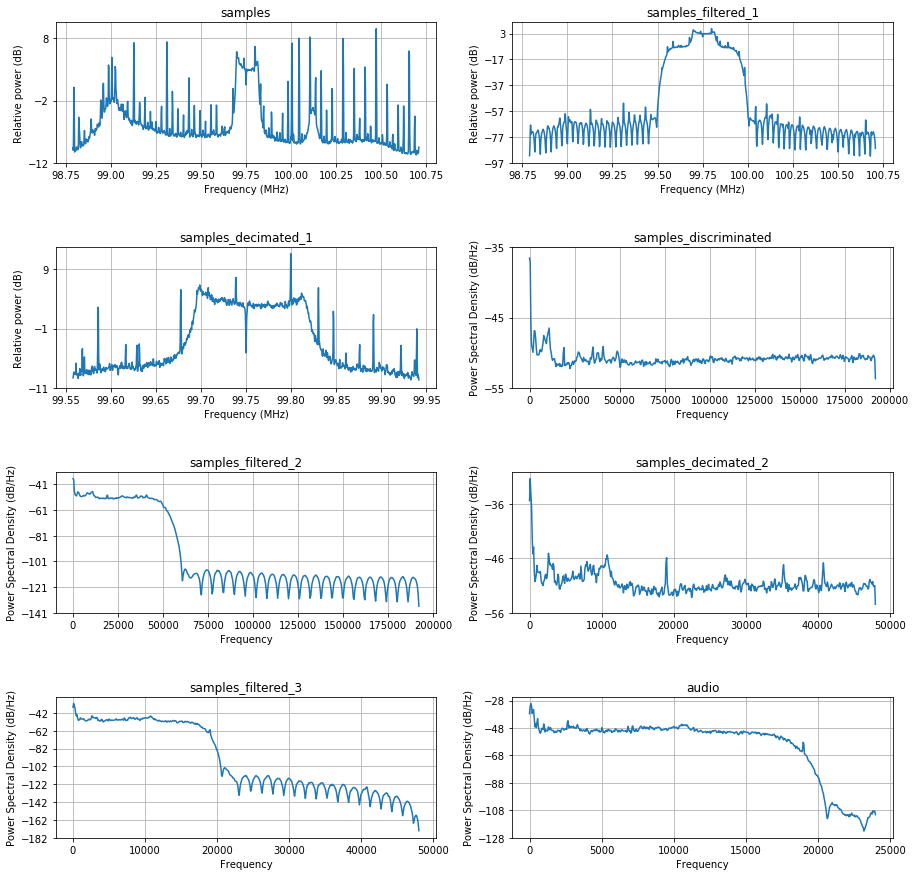

[ 0.00000000e+00  3.84907146e-08  1.41337250e-06 -3.92468591e-06
 -2.07572784e-05  2.14217520e-04 -1.31158297e-03  1.72791168e-03
 -7.11902610e-04 -2.22783615e-03  6.72084352e-03 -7.82412837e-03
  3.99362575e-03  1.00346981e-02 -2.62647507e-02  3.21866276e-02
 -1.52188862e-02 -3.23751580e-02  8.97814009e-02 -1.17238781e-01]


In [29]:
from IPython.display import Audio

audio, _, _ = fm_audio(complex_samples, plot=True)
print(audio[0:20])
Audio(audio, rate=48000)

In [30]:
sdr.close()